# Parthiban – Research & Evaluation Analysis
**Project:** Predicting Next-Year GDP Growth Across Countries

This notebook evaluates Sami's existing model predictions, compares errors by region and income group, creates charts, and calculates country-cluster bootstrap confidence intervals.

## Input files
This notebook supports **all upload/loading methods automatically** (Jupyter, VS Code, or Google Colab):
- `predictions_all_models.csv`
- `country_groups.csv`

**How to provide the CSVs:**
1. **Folder / Path:** Place both CSVs in the same folder as this notebook (or update `DATA_DIR` in Section 1).
2. **Two Separate Upload Buttons (Jupyter / VS Code):** Run Section 2A, select each file individually, then run Section 2B.
3. **Google Colab Picker:** If running in Colab and files aren't in the folder yet, Section 2B will automatically open Colab's file upload prompt.

This notebook analyses existing predictions; it does not retrain the models.


In [1]:
# 1. Imports and configuration
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

# Option A: Set the folder where your CSV files are stored (defaults to current folder)
DATA_DIR = Path(".")
PREDICTIONS_FILE = DATA_DIR / "predictions_all_models.csv"
COUNTRY_GROUPS_FILE = DATA_DIR / "country_groups.csv"

OUTPUT_DIR = Path("Parthiban_Outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

BOOTSTRAP_REPETITIONS = 1000
RANDOM_SEED = 42

print("Data folder:", DATA_DIR.resolve())
print("Output folder:", OUTPUT_DIR.resolve())


Data folder: /content
Output folder: /content/Parthiban_Outputs


In [2]:
# 2A. Optional Upload Widgets (for local Jupyter / VS Code)
# Skip this cell if you already placed both CSV files in DATA_DIR or are using Google Colab.
try:
    import ipywidgets as widgets
    from IPython.display import display

    pred_upload = widgets.FileUpload(
        accept=".csv",
        multiple=False,
        description="1. Predictions CSV"
    )
    groups_upload = widgets.FileUpload(
        accept=".csv",
        multiple=False,
        description="2. Country Groups CSV"
    )

    display(widgets.VBox([
        widgets.HTML(
            "<b>Upload each CSV using its button below, then run the next cell (2B):</b>"
        ),
        widgets.HBox([pred_upload, groups_upload])
    ]))
except ImportError:
    pred_upload = None
    groups_upload = None
    print("ipywidgets not installed. Place CSVs in DATA_DIR or use Google Colab upload in the next cell.")


In [3]:
# 2B. Load & validate both CSV files (supports Widgets, Disk/Folder, and Google Colab)
def extract_widget_bytes(upload_widget):
    """Extract {filename: bytes} from ipywidgets 7 or 8 FileUpload widget."""
    if upload_widget is None or not getattr(upload_widget, "value", None):
        return {}
    value = upload_widget.value
    files = {}
    if isinstance(value, dict):
        for fname, item in value.items():
            files[fname] = item["content"]
    elif isinstance(value, (tuple, list)):
        for item in value:
            if item.get("name"):
                files[item["name"]] = item["content"]
    return files

# Save any widget-uploaded files to disk so re-runs don't lose them
for widget_obj, target_path in [
    (globals().get("pred_upload"), PREDICTIONS_FILE),
    (globals().get("groups_upload"), COUNTRY_GROUPS_FILE),
]:
    uploaded_map = extract_widget_bytes(widget_obj)
    if uploaded_map:
        _, content = next(iter(uploaded_map.items()))
        target_path.parent.mkdir(parents=True, exist_ok=True)
        target_path.write_bytes(content)
        print(f"Saved uploaded file to: {target_path}")

# If running in Google Colab and either file is still missing, trigger Colab's native uploader
if not PREDICTIONS_FILE.exists() or not COUNTRY_GROUPS_FILE.exists():
    try:
        from google.colab import files as colab_files
        print("Select both predictions_all_models.csv and country_groups.csv in the Colab upload dialog:")
        colab_uploaded = colab_files.upload()
        for fname, content in colab_uploaded.items():
            dest = DATA_DIR / fname
            dest.write_bytes(content)
            print(f"Uploaded via Colab: {dest}")
    except ImportError:
        pass

def read_required_csv(file_path: Path):
    if file_path.exists():
        print(f"Loaded file: {file_path}")
        return pd.read_csv(file_path)
    raise FileNotFoundError(
        f"{file_path} was not found. Upload it in Cell 2A or place it in {DATA_DIR.resolve()}."
    )

pred = read_required_csv(PREDICTIONS_FILE)
groups = read_required_csv(COUNTRY_GROUPS_FILE)

required_pred = {
    "Country Code", "target_year", "split",
    "actual", "predicted", "model"
}
required_groups = {"Country Code", "region", "income_group"}

missing_pred = required_pred - set(pred.columns)
missing_groups = required_groups - set(groups.columns)

if missing_pred:
    raise ValueError(f"Missing columns in predictions file: {sorted(missing_pred)}")
if missing_groups:
    raise ValueError(f"Missing columns in country groups file: {sorted(missing_groups)}")

print("Predictions shape:", pred.shape)
print("Country groups shape:", groups.shape)
print("Models:", sorted(pred["model"].dropna().astype(str).unique()))


Select both predictions_all_models.csv and country_groups.csv in the Colab upload dialog:


Saving country_groups.csv to country_groups.csv
Saving predictions_all_models.csv to predictions_all_models.csv
Uploaded via Colab: country_groups.csv
Uploaded via Colab: predictions_all_models.csv
Loaded file: predictions_all_models.csv
Loaded file: country_groups.csv
Predictions shape: (10178, 9)
Country groups shape: (296, 3)
Models: ['Country mean', 'Global mean', 'Gradient Boosting', 'Lasso', 'Naive', 'Random Forest', 'Ridge']


In [4]:
# 3. Merge country classifications and select the final test period
# Remove any existing group columns first to avoid duplicate column names.
pred = pred.drop(columns=["region", "income_group"], errors="ignore")

if groups["Country Code"].duplicated().any():
    duplicates = groups.loc[
        groups["Country Code"].duplicated(keep=False), "Country Code"
    ].unique()
    raise ValueError(
        "country_groups.csv has duplicate Country Code values. "
        f"Examples: {duplicates[:10]}"
    )

df = pred.merge(
    groups[["Country Code", "region", "income_group"]],
    on="Country Code",
    how="left",
    validate="many_to_one"
)

print("Rows with missing region:", df["region"].isna().sum())
print("Rows with missing income group:", df["income_group"].isna().sum())

# Keep Sami's final held-out test years (2021–2024).
df = df[df["split"].astype(str).str.lower().eq("test")].copy()

# Convert numeric columns safely.
for col in ["actual", "predicted", "target_year"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=[
    "Country Code", "target_year", "actual", "predicted",
    "model", "region", "income_group"
]).copy()

# Exclude World Bank aggregate/non-geographical classifications.
df = df[
    ~df["region"].astype(str).str.strip().str.lower().eq("aggregates")
].copy()
df = df[
    ~df["income_group"].astype(str).str.strip().str.lower().eq("aggregates")
].copy()

if df.empty:
    raise ValueError(
        "No usable test observations remain. Check the split values and metadata."
    )

print("\nTest years:", int(df["target_year"].min()), "-", int(df["target_year"].max()))
print("Test prediction rows:", len(df))
print("Unique countries:", df["Country Code"].nunique())
print("Models in test data:", sorted(df["model"].unique()))


Rows with missing region: 0
Rows with missing income group: 0

Test years: 2021 - 2024
Test prediction rows: 5761
Unique countries: 210
Models in test data: ['Country mean', 'Global mean', 'Gradient Boosting', 'Lasso', 'Naive', 'Random Forest', 'Ridge']


In [5]:
# 4. Calculate prediction errors
df["error"] = df["actual"] - df["predicted"]
df["absolute_error"] = df["error"].abs()
df["squared_error"] = df["error"] ** 2

def calculate_metrics(data):
    return pd.Series({
        "MAE": data["absolute_error"].mean(),
        "RMSE": np.sqrt(data["squared_error"].mean()),
        "Observations": len(data),
        "Countries": data["Country Code"].nunique()
    })

overall_results = (
    df.groupby("model", sort=True)
      .apply(calculate_metrics)
      .reset_index()
)
overall_results.to_csv(OUTPUT_DIR / "overall_test_metrics.csv", index=False)

print("OVERALL TEST RESULTS")
display(overall_results.round(3))


OVERALL TEST RESULTS


/tmp/ipykernel_1561/2837537561.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(calculate_metrics)


,model,MAE,RMSE,Observations,Countries
0,Country mean,3.543,6.390,823.0,210.0
1,Global mean,3.345,6.243,823.0,210.0
2,Gradient Boosting,3.474,6.463,823.0,210.0
3,Lasso,3.705,6.748,823.0,210.0
4,Naive,5.813,10.536,823.0,210.0
5,Random Forest,3.487,6.352,823.0,210.0
6,Ridge,3.715,6.756,823.0,210.0


In [6]:
# 5. Error analysis by geographical region
regional_results = (
    df.groupby(["region", "model"], sort=True)
      .apply(calculate_metrics)
      .reset_index()
)

regional_results.to_csv(
    OUTPUT_DIR / "regional_error_analysis.csv", index=False
)

print("REGIONAL ERROR ANALYSIS")
display(regional_results.round(3))


REGIONAL ERROR ANALYSIS


/tmp/ipykernel_1561/1800387217.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(calculate_metrics)


,region,model,MAE,RMSE,Observations,Countries
0,East Asia & Pacific,Country mean,4.263,8.496,138.0,36.0
1,East Asia & Pacific,Global mean,4.094,8.483,138.0,36.0
2,East Asia & Pacific,Gradient Boosting,4.194,8.798,138.0,36.0
3,East Asia & Pacific,Lasso,4.251,8.989,138.0,36.0
4,East Asia & Pacific,Naive,6.869,14.392,138.0,36.0
5,East Asia & Pacific,Random Forest,4.139,8.681,138.0,36.0
6,East Asia & Pacific,Ridge,4.267,9.003,138.0,36.0
7,Europe & Central Asia,Country mean,3.060,4.543,220.0,56.0
8,Europe & Central Asia,Global mean,3.061,4.435,220.0,56.0
9,Europe & Central Asia,Gradient Boosting,3.229,4.928,220.0,56.0


In [7]:
# 6. Error analysis by World Bank income group
income_results = (
    df.groupby(["income_group", "model"], sort=True)
      .apply(calculate_metrics)
      .reset_index()
)

income_results.to_csv(
    OUTPUT_DIR / "income_group_error_analysis.csv", index=False
)

print("INCOME-GROUP ERROR ANALYSIS")
display(income_results.round(3))


INCOME-GROUP ERROR ANALYSIS


/tmp/ipykernel_1561/668746898.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(calculate_metrics)


,income_group,model,MAE,RMSE,Observations,Countries
0,High income,Country mean,4.121,7.736,317.0,83.0
1,High income,Global mean,3.805,7.621,317.0,83.0
2,High income,Gradient Boosting,4.094,7.876,317.0,83.0
3,High income,Lasso,4.439,8.214,317.0,83.0
4,High income,Naive,7.023,12.724,317.0,83.0
5,High income,Random Forest,4.047,7.738,317.0,83.0
6,High income,Ridge,4.463,8.231,317.0,83.0
7,Low income,Country mean,3.156,5.847,82.0,21.0
8,Low income,Global mean,2.969,5.640,82.0,21.0
9,Low income,Gradient Boosting,2.518,5.066,82.0,21.0


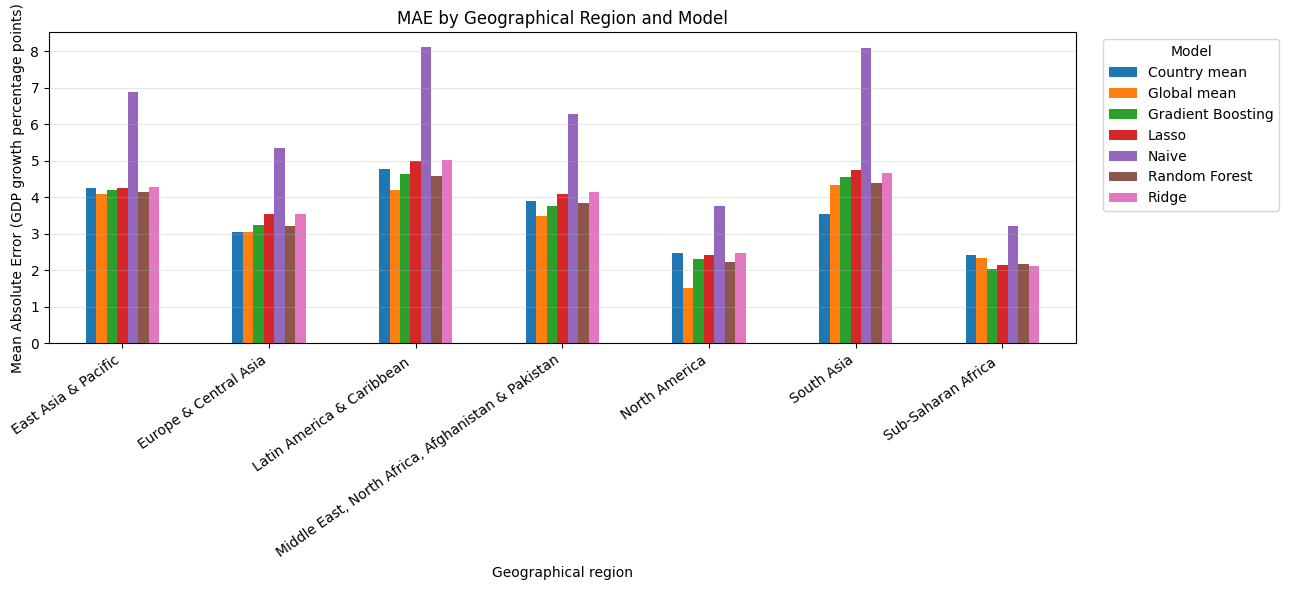

In [8]:
# 7. Graph 1 – MAE by geographical region
pivot = regional_results.pivot(
    index="region", columns="model", values="MAE"
)

ax = pivot.plot(kind="bar", figsize=(13, 6))
ax.set_title("MAE by Geographical Region and Model")
ax.set_xlabel("Geographical region")
ax.set_ylabel("Mean Absolute Error (GDP growth percentage points)")
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "regional_MAE.png", dpi=300, bbox_inches="tight")
plt.show()


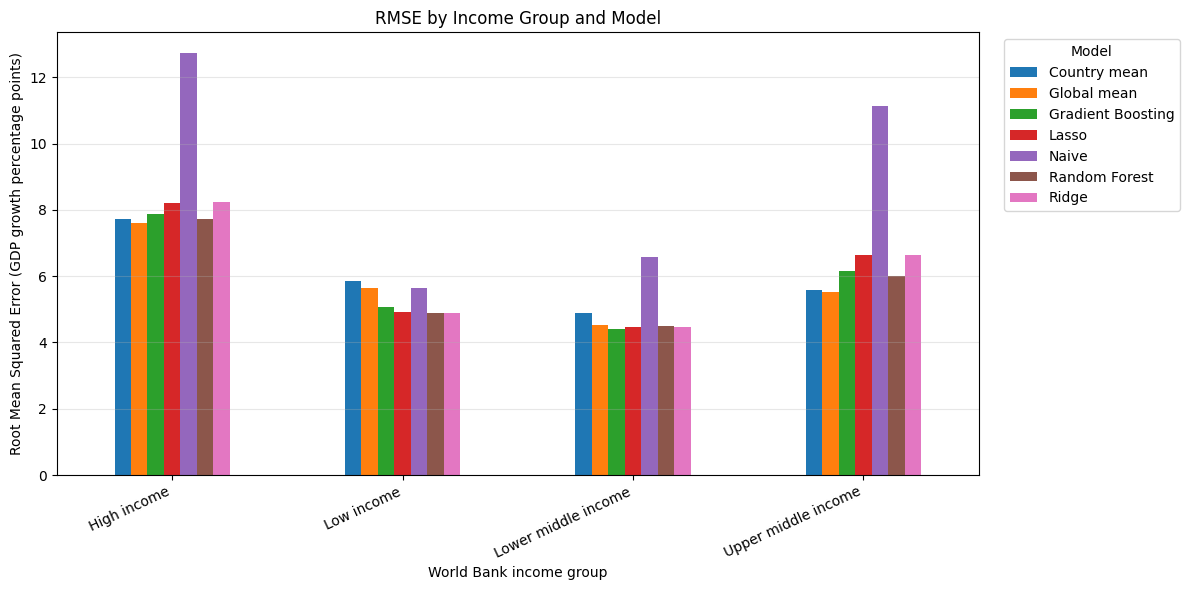

In [9]:
# 8. Graph 2 – RMSE by income group
pivot = income_results.pivot(
    index="income_group", columns="model", values="RMSE"
)

ax = pivot.plot(kind="bar", figsize=(12, 6))
ax.set_title("RMSE by Income Group and Model")
ax.set_xlabel("World Bank income group")
ax.set_ylabel("Root Mean Squared Error (GDP growth percentage points)")
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "income_group_RMSE.png", dpi=300, bbox_inches="tight")
plt.show()


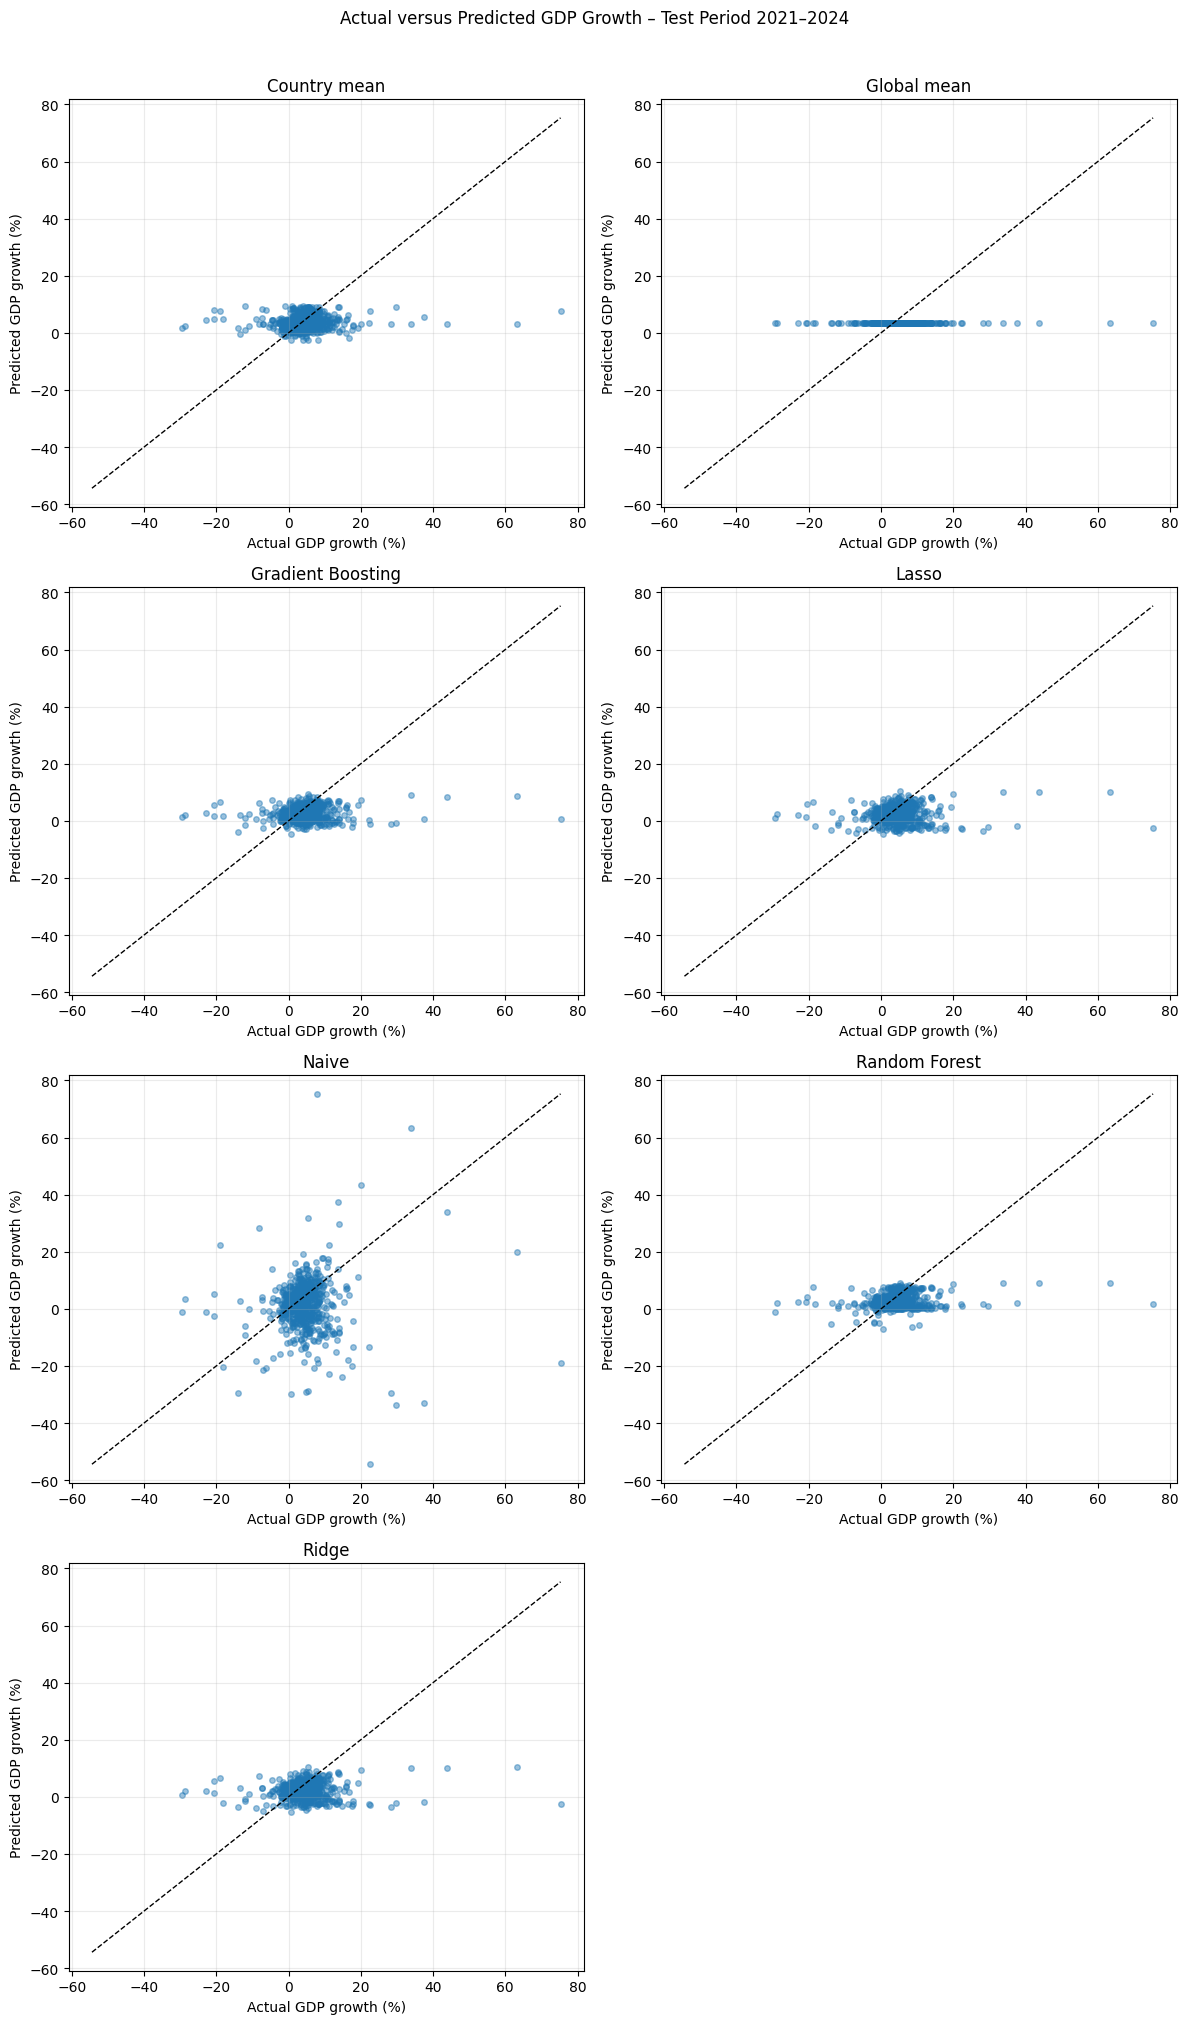

In [10]:
# 9. Graph 3 – Actual versus predicted GDP growth
# Separate panels make the seven methods easier to inspect.
models = sorted(df["model"].unique())
ncols = 2
nrows = int(np.ceil(len(models) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(12, 5 * nrows), squeeze=False)
axes = axes.ravel()

global_min = min(df["actual"].min(), df["predicted"].min())
global_max = max(df["actual"].max(), df["predicted"].max())

for ax, model in zip(axes, models):
    subset = df[df["model"] == model]
    ax.scatter(subset["actual"], subset["predicted"], alpha=0.45, s=16)
    ax.plot([global_min, global_max], [global_min, global_max], "k--", linewidth=1)
    ax.set_title(model)
    ax.set_xlabel("Actual GDP growth (%)")
    ax.set_ylabel("Predicted GDP growth (%)")
    ax.grid(alpha=0.25)

for ax in axes[len(models):]:
    ax.set_visible(False)

fig.suptitle("Actual versus Predicted GDP Growth – Test Period 2021–2024", y=1.01)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "actual_vs_predicted_by_model.png", dpi=300, bbox_inches="tight")
plt.show()


## 10. Country-level bootstrap confidence intervals

The bootstrap samples countries with replacement and keeps all available test-year observations for each selected country together. This accounts for repeated country observations when estimating uncertainty in the group-level MAE and RMSE.

The intervals are descriptive 95% percentile bootstrap intervals. They are conditional on the observed test period and do not represent all sources of forecasting uncertainty.


In [11]:
# 10. Bootstrap function
def country_cluster_bootstrap(data, repetitions=1000, seed=42):
    country_ids = data["Country Code"].dropna().unique()

    if len(country_ids) < 2:
        return None

    rng = np.random.default_rng(seed)

    # Keep each country's observations together.
    country_rows = {
        country: data.loc[data["Country Code"] == country,
                          ["absolute_error", "squared_error"]].to_numpy()
        for country in country_ids
    }

    mae_values = np.empty(repetitions)
    rmse_values = np.empty(repetitions)

    for b in range(repetitions):
        sampled_ids = rng.choice(
            country_ids, size=len(country_ids), replace=True
        )
        sampled_rows = np.concatenate(
            [country_rows[country] for country in sampled_ids],
            axis=0
        )

        mae_values[b] = sampled_rows[:, 0].mean()
        rmse_values[b] = np.sqrt(sampled_rows[:, 1].mean())

    return {
        "MAE_CI_Lower": np.percentile(mae_values, 2.5),
        "MAE_CI_Upper": np.percentile(mae_values, 97.5),
        "RMSE_CI_Lower": np.percentile(rmse_values, 2.5),
        "RMSE_CI_Upper": np.percentile(rmse_values, 97.5),
        "Bootstrap_Repetitions": repetitions,
        "Countries": len(country_ids)
    }


In [12]:
# 11. Bootstrap confidence intervals by region and model
regional_bootstrap = []

for (region, model), group in df.groupby(["region", "model"], sort=True):
    result = country_cluster_bootstrap(
        group, repetitions=BOOTSTRAP_REPETITIONS,
        seed=RANDOM_SEED
    )
    if result is not None:
        regional_bootstrap.append({
            "region": region,
            "model": model,
            **result
        })

regional_ci = pd.DataFrame(regional_bootstrap)
regional_ci.to_csv(
    OUTPUT_DIR / "regional_bootstrap_CI.csv", index=False
)

print("REGIONAL BOOTSTRAP 95% CONFIDENCE INTERVALS")
display(regional_ci.round(3))


REGIONAL BOOTSTRAP 95% CONFIDENCE INTERVALS


,region,model,MAE_CI_Lower,MAE_CI_Upper,RMSE_CI_Lower,RMSE_CI_Upper,Bootstrap_Repetitions,Countries
0,East Asia & Pacific,Country mean,2.770,6.291,4.277,13.174,1000,36
1,East Asia & Pacific,Global mean,2.714,6.167,4.083,13.382,1000,36
2,East Asia & Pacific,Gradient Boosting,2.716,6.462,4.058,13.903,1000,36
3,East Asia & Pacific,Lasso,2.804,6.532,4.161,14.250,1000,36
4,East Asia & Pacific,Naive,4.096,11.748,5.975,23.552,1000,36
5,East Asia & Pacific,Random Forest,2.729,6.317,4.089,13.677,1000,36
6,East Asia & Pacific,Ridge,2.825,6.538,4.192,14.258,1000,36
7,Europe & Central Asia,Country mean,2.562,3.521,3.558,5.605,1000,56
8,Europe & Central Asia,Global mean,2.627,3.507,3.423,5.550,1000,56
9,Europe & Central Asia,Gradient Boosting,2.784,3.711,3.943,5.937,1000,56


In [13]:
# 12. Bootstrap confidence intervals by income group and model
income_bootstrap = []

for (income_group, model), group in df.groupby(
    ["income_group", "model"], sort=True
):
    result = country_cluster_bootstrap(
        group, repetitions=BOOTSTRAP_REPETITIONS,
        seed=RANDOM_SEED
    )
    if result is not None:
        income_bootstrap.append({
            "income_group": income_group,
            "model": model,
            **result
        })

income_ci = pd.DataFrame(income_bootstrap)
income_ci.to_csv(
    OUTPUT_DIR / "income_bootstrap_CI.csv", index=False
)

print("INCOME-GROUP BOOTSTRAP 95% CONFIDENCE INTERVALS")
display(income_ci.round(3))


INCOME-GROUP BOOTSTRAP 95% CONFIDENCE INTERVALS


,income_group,model,MAE_CI_Lower,MAE_CI_Upper,RMSE_CI_Lower,RMSE_CI_Upper,Bootstrap_Repetitions,Countries
0,High income,Country mean,3.224,5.522,4.509,10.972,1000,83
1,High income,Global mean,2.905,5.220,4.106,10.995,1000,83
2,High income,Gradient Boosting,3.252,5.392,4.749,11.148,1000,83
3,High income,Lasso,3.604,5.719,5.238,11.476,1000,83
4,High income,Naive,5.586,9.182,8.486,17.745,1000,83
5,High income,Random Forest,3.225,5.309,4.679,10.970,1000,83
6,High income,Ridge,3.626,5.747,5.268,11.494,1000,83
7,Low income,Country mean,1.802,5.003,2.267,8.807,1000,21
8,Low income,Global mean,1.764,4.713,2.231,8.653,1000,21
9,Low income,Gradient Boosting,1.508,3.924,2.137,7.650,1000,21


In [14]:
# 13. Identify the lowest-MAE model in each region and income group
best_by_region = (
    regional_results.loc[
        regional_results.groupby("region")["MAE"].idxmin()
    ].sort_values("region")
)

best_by_income = (
    income_results.loc[
        income_results.groupby("income_group")["MAE"].idxmin()
    ].sort_values("income_group")
)

best_by_region.to_csv(
    OUTPUT_DIR / "best_model_by_region.csv", index=False
)
best_by_income.to_csv(
    OUTPUT_DIR / "best_model_by_income.csv", index=False
)

print("LOWEST-MAE MODEL BY REGION")
display(best_by_region.round(3))

print("LOWEST-MAE MODEL BY INCOME GROUP")
display(best_by_income.round(3))


LOWEST-MAE MODEL BY REGION


,region,model,MAE,RMSE,Observations,Countries
1,East Asia & Pacific,Global mean,4.094,8.483,138.0,36.0
7,Europe & Central Asia,Country mean,3.060,4.543,220.0,56.0
15,Latin America & Caribbean,Global mean,4.190,8.069,159.0,41.0
22,"Middle East, North Africa, Afghanistan & Pakistan",Global mean,3.476,5.997,86.0,22.0
29,North America,Global mean,1.501,1.653,12.0,3.0
35,South Asia,Country mean,3.530,7.440,24.0,6.0
44,Sub-Saharan Africa,Gradient Boosting,2.022,3.664,184.0,46.0


LOWEST-MAE MODEL BY INCOME GROUP


,income_group,model,MAE,RMSE,Observations,Countries
1,High income,Global mean,3.805,7.621,317.0,83.0
13,Low income,Ridge,2.398,4.884,82.0,21.0
16,Lower middle income,Gradient Boosting,2.588,4.421,188.0,47.0
22,Upper middle income,Global mean,3.294,5.521,236.0,59.0


In [15]:
# 14. Final output inventory
print("Analysis completed.")
print("Output directory:", OUTPUT_DIR.resolve())
print("\nGenerated files:")

for path in sorted(OUTPUT_DIR.iterdir()):
    if path.is_file():
        print(f"- {path.name} ({path.stat().st_size:,} bytes)")


Analysis completed.
Output directory: /content/Parthiban_Outputs

Generated files:
- actual_vs_predicted_by_model.png (965,172 bytes)
- best_model_by_income.csv (351 bytes)
- best_model_by_region.csv (619 bytes)
- income_bootstrap_CI.csv (3,118 bytes)
- income_group_RMSE.png (222,965 bytes)
- income_group_error_analysis.csv (2,104 bytes)
- overall_test_metrics.csv (456 bytes)
- regional_MAE.png (330,605 bytes)
- regional_bootstrap_CI.csv (5,667 bytes)
- regional_error_analysis.csv (3,991 bytes)
